In [6]:
from collections import Counter  # Cuenta los votos de cada clase.

import matplotlib.pyplot as plt  # Dibuja la gráfica y la guarda como imagen.
import numpy as np               # Maneja arreglos y calcula distancias.

from sklearn.datasets import make_blobs                 # Genera puntos agrupados.
from sklearn.model_selection import train_test_split    # Separa los datos.
from sklearn.neighbors import KNeighborsClassifier      # Valida nuestro K-NN.

In [7]:
# X contiene las coordenadas de los puntos.
# y contiene sus etiquetas reales: 0, 1 o 2.
X, y = make_blobs(
    n_samples=300,                         # Número total de puntos.
    centers=[(-3, -2), (0, 2), (3, -2)],   # Un centro por clase.
    cluster_std=1.4,                       # Dispersión alrededor de cada centro.
    random_state=42,                      # Permite reproducir los mismos datos.
)

# Guardamos 225 puntos para entrenamiento y 75 para evaluar el algoritmo.
X_entreno, X_prueba, y_entreno, y_prueba = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,  # Mantiene la proporción de cada clase en ambos conjuntos.
)

print(f"Entrenamiento: {len(X_entreno)} | Prueba: {len(X_prueba)}")

Entrenamiento: 225 | Prueba: 75


In [8]:
def predecir_knn(X_entreno, y_entreno, X_nuevo, k):
    """Devuelve una clase predicha para cada punto de X_nuevo."""
    predicciones = []

    for punto in X_nuevo:
        # Calcula la distancia euclidiana del punto a cada fila de X_entreno.
        # axis=1 indica que NumPy calcula una distancia por fila.
        distancias = np.linalg.norm(X_entreno - punto, axis=1)

        # argsort devuelve los índices ordenados de la menor distancia a la mayor.
        # [:k] toma solo los índices de los k puntos más cercanos.
        vecinos = np.argsort(distancias, kind="stable")[:k]

        # Busca las etiquetas de esos vecinos y cuenta un voto por vecino.
        # Por ejemplo, [0, 2, 2, 0, 2] da dos votos a 0 y tres votos a 2.
        votos = Counter(y_entreno[vecinos])

        # Elige la clase con más votos. Al ordenar antes las etiquetas,
        # max devuelve la etiqueta menor si hay empate en votos.
        clase = max(sorted(votos), key=votos.get)
        predicciones.append(clase)

    return np.array(predicciones)

In [4]:
# Los dos clasificadores usan cinco vecinos y distancia euclidiana.
k = 5
y_manual = predecir_knn(X_entreno, y_entreno, X_prueba, k)

# Con weights="uniform", cada vecino aporta un voto.
modelo = KNeighborsClassifier(
    n_neighbors=k, metric="euclidean", weights="uniform"
)
modelo.fit(X_entreno, y_entreno)
y_sklearn = modelo.predict(X_prueba)

# Cada comparación devuelve True para los aciertos y False para los errores.
# np.mean calcula la proporción de aciertos.
print(f"Exactitud manual:       {np.mean(y_manual == y_prueba):.2%}")
print(f"Exactitud scikit-learn: {np.mean(y_sklearn == y_prueba):.2%}")

# Contamos en cuántos puntos los dos modelos predicen la misma clase.
print(f"Predicciones iguales:   {np.sum(y_manual == y_sklearn)}/{len(y_prueba)}")


Exactitud manual:       94.67%
Exactitud scikit-learn: 94.67%
Predicciones iguales:   75/75


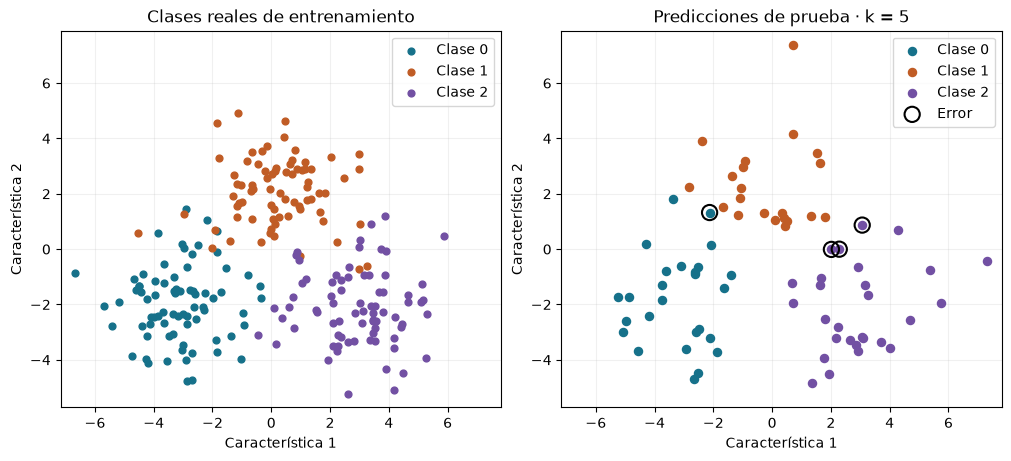

In [9]:
# Creamos una figura con dos paneles y un color para cada clase.
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
colores = ["#16718a", "#c05c25", "#7250a3"]

for clase, color in enumerate(colores):
    # Estas condiciones seleccionan los puntos que pertenecen a cada clase.
    entreno = y_entreno == clase
    predichos = y_manual == clase
    etiqueta = f"Clase {clase}"

    # .T organiza las coordenadas en dos filas y * las pasa como x e y.
    # Izquierda: coloreamos los puntos según su clase real.
    ejes[0].scatter(*X_entreno[entreno].T, color=color, s=24, label=etiqueta)

    # Derecha: coloreamos los puntos según la clase que predijo nuestro K-NN.
    ejes[1].scatter(*X_prueba[predichos].T, color=color, s=34, label=etiqueta)

# Dibuja un círculo sin relleno alrededor de cada predicción incorrecta.
errores = y_manual != y_prueba
ejes[1].scatter(
    *X_prueba[errores].T,
    s=120, facecolors="none", edgecolors="black",
    linewidths=1.5, label="Error",
)

ejes[0].set_title("Clases reales de entrenamiento")
ejes[1].set_title(f"Predicciones de prueba · k = {k}")

# Usamos los mismos límites en ambos paneles para comparar sus posiciones.
for eje in ejes:
    eje.set_xlabel("Característica 1")
    eje.set_ylabel("Característica 2")
    eje.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
    eje.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    eje.grid(alpha=0.18)
    eje.set_axisbelow(True)  # Coloca la cuadrícula detrás de los puntos.
    eje.legend(loc="upper right")

# Guarda el PNG en el directorio de trabajo y muestra la figura en Jupyter.
fig.savefig("knn_blobs.png", dpi=180)
plt.show()